In [126]:
import json

file_path = 'refined_output.jsonl'

# Initialize a dictionary to collect predicted diseases for each gene
predicted_diseases_dict = {}

# Open the file and read line by line
with open(file_path, 'r') as file:
    for line in file:
        # Parse the JSON object
        data = json.loads(line)
        
        # Extract the gene name from the "custom_id" field
        custom_id = data['custom_id']
        gene_name = custom_id.split('-')[1]  # Extracting the gene name part
        
        # Extract the diseases from the response body
        message_content = data['response']['body']['choices'][0]['message']['content']
        disease_list = message_content.split(", ")

        # Store the diseases in the dictionary under the gene name
        predicted_diseases_dict[gene_name] = disease_list

# Print the dictionary of predicted diseases
print(predicted_diseases_dict)

{'ADAMTS10': ['Weill-Marchesani Syndrome - Autosomal Recessive', 'Hereditary Diffuse Gastric Cancer', 'Malignant neoplasm of liver', 'Malignant neoplasm of breast', 'Hereditary Non-Polyposis Colorectal Neoplasms', 'Malignant neoplasm of prostate', 'Lymphoma - Non-Hodgkin', 'Schizophrenia', 'Autism Spectrum Disorders', 'Venous Thromboembolism'], 'RPL35A': ['Hereditary Diffuse Gastric Cancer', 'Colorectal Carcinoma', 'Obesity', 'Malignant neoplasm of breast', 'Malignant neoplasm of prostate', 'Schizophrenia', 'Diabetes Mellitus - Non-Insulin-Dependent', 'Primary biliary cirrhosis', 'Malignant neoplasm of liver', 'Lupus Erythematosus - Systemic'], 'DOLK': ['Hereditary Diffuse Gastric Cancer', 'Myeloid Leukemia - Chronic', 'Autistic Disorder', 'Obesity', 'Congenital disorder of glycosylation type 1q', 'Schizophrenia', 'Malignant neoplasm of breast', 'Mitochondrial Myopathy', 'Leigh Syndrome', 'Liver carcinoma'], 'ACSL4': ['Liver carcinoma', 'Schizophrenia', 'Malignant neoplasm of breast', 

In [128]:
all_predicted_diseases = [disease for diseases in predicted_diseases_dict.values() for disease in diseases]

In [211]:
all_predicted_diseases.sort()
all_predicted_diseases

['ABCA4',
 'Abdominal Aortic Aneurysm',
 'Abdominal Aortic Aneurysm',
 'Abetalipoproteinemia',
 'Achromatopsia',
 'Achromatopsia',
 'Achromatopsia',
 'Achromatopsia 3',
 'Acne Inversa - Familial - 3',
 'Acromegaly',
 'Acromegaly',
 'Acromegaly',
 'Acromesomelic Dysplasia',
 'Action myoclonus-renal failure syndrome',
 'Acute Lymphoblastic Leukemia',
 'Acute Myeloid Leukemia',
 'Acute Myeloid Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 'Acute Promyelocytic Leukemia',
 

In [131]:
df = pd.read_csv('/Users/eshav/Downloads/curated_Disgenet.csv', delimiter=";")

for indx, row in df.iterrows():
    if "," in row['diseaseName']:
        df.at[indx, 'diseaseName'] = row['diseaseName'].replace(',', ' -')

real_diseases = list(df['diseaseName'])

In [118]:
real_diseases

['Hepatomegaly',
 'Schizophrenia',
 "Alzheimer's Disease",
 'Malignant tumor of colon',
 'Colonic Neoplasms',
 'Presenile dementia',
 'Mental Depression',
 'Depressive disorder',
 'Hepatolenticular Degeneration',
 'Kidney Failure - Acute',
 'Liver Cirrhosis',
 'Liver Cirrhosis - Experimental',
 'Lung diseases',
 'Lung Neoplasms',
 'Nephrotic Syndrome',
 'Hepatocellular Adenoma',
 'Fibrosis - Liver',
 'Malignant neoplasm of lung',
 'Familial Alzheimer Disease (FAD)',
 'Alzheimer Disease - Late Onset',
 'Acute Confusional Senile Dementia',
 "Alzheimer's Disease - Focal Onset",
 'Alzheimer Disease - Early Onset',
 'Hepatic Form of Wilson Disease',
 'Acute Kidney Insufficiency',
 'Liver carcinoma',
 'Acute kidney injury',
 'alpha-2-Macroglobulin Deficiency',
 'Alcoholic Intoxication - Chronic',
 'Autosome Abnormalities',
 'Malignant neoplasm of urinary bladder',
 'Bladder Neoplasm',
 'Malignant Neoplasms',
 'Chromosome Aberrations',
 'Drug toxicity',
 'Neoplasms',
 'Dermatitis - Occupation

In [168]:
hallucinations = []

for disease in all_predicted_diseases:
    match_found = False
    if disease in real_diseases:
        match_found = True
    if (not match_found):
        for real_disease in real_diseases:
            if (disease.lower()  in real_disease.lower()):
                match_found = True
    if (not match_found):
        hallucinations.append(disease)
    # if disease not in real_diseases:
    #     hallucinations.append(disease)

In [176]:
hallucinations

['Hereditary Non-Polyposis Colorectal Neoplasms',
 'Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Tuberous Sclerosis.',
 'Schizophrenia.',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant.',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Hereditary Nonpolyposis Colorectal Cancer.',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Se

### take out the period in front, the lowercase and and, and then levishtan distance

In [172]:
corrected_hallucinations = []

for disease in hallucinations:
    if disease.endswith("."):
        disease = disease[:-1]
    corrected_hallucinations.append(disease)

In [177]:
corrected_hallucinations

['Hereditary Non-Polyposis Colorectal Neoplasms',
 'Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Tuberous Sclerosis',
 'Schizophrenia',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Hereditary Nonpolyposis Colorectal Cancer',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous

In [178]:
filtered_diseases = []

for disease in corrected_hallucinations:
    if disease[0].islower():
        cleaned_disease = disease
        if cleaned_disease.startswith('and '):
            cleaned_disease = cleaned_disease[len('and '):].strip()
        filtered_diseases.append(cleaned_disease)
    else:
        filtered_diseases.append(disease)

filtered_diseases

['Hereditary Non-Polyposis Colorectal Neoplasms',
 'Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Tuberous Sclerosis',
 'Schizophrenia',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Hereditary Nonpolyposis Colorectal Cancer',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous

In [164]:
filtered_diseases

['Hereditary Non-Polyposis Colorectal Neoplasms',
 'Mitochondrial Myopathy',
 'Leigh Syndrome',
 'Leigh Syndrome',
 'Gastric Carcinoma',
 'Myelodysplastic Syndrome',
 'Alzheimer Disease',
 'Systemic Lupus Erythematosus',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Gastric Cancer',
 'Liver Carcinoma',
 'Malignant Mesothelioma',
 'Malignant Neoplasm of Breast',
 'Tuberous Sclerosis',
 'Myeloproliferative Disorder',
 'Thalassemia',
 'Schizophrenia',
 'Colorectal Cancer',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'Ectopia lentis',
 'Graves disease',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Brugada syndrome',
 'Short QT syndrome',
 'Atrial fibrillation',
 'Hypertrophic cardiomyopathy',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Long QT syndrome',
 'Sudden cardiac death',
 'Ventricular tachycardia',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Liver disease',
 'Bile acid synth

In [66]:
filtered_diseases2 = []

for disease in filtered_diseases:
    if disease[0].islower():
        cleaned_disease = disease[0].upper() + disease[1:]
    else:
        cleaned_disease = disease
    filtered_diseases2.append(cleaned_disease)

filtered_diseases2

['Thyroid Cancer - Nonmedullary',
 'KIF1A',
 'Lung adenocarcinoma',
 'GABRB2',
 'Osteogenesis imperfecta type VI',
 'Idiopathic Pulmonary Hypertension',
 'Myeloproliferative Disorder',
 'Dandy-Walker Malformation',
 'Rheumatoid arthritis - systemic juvenile',
 'Bardet-Biedl syndrome 10',
 'Neonatal cholestasis',
 'Amyotrophic Lateral Sclerosis',
 'Neurogenetic Syndrome with Cardiac Malformation',
 'Myelodysplastic syndrome',
 ' Congenital Anemia',
 'Autism spectrum disorders',
 'Night Blindness - Congenital Stationary - Type 2A',
 'Abetalipoproteinemia',
 'Lamellar Ichthyosis',
 'Polycystic Kidney Disease',
 'Systemic juvenile idiopathic arthritis',
 'Type II',
 'NRXN1',
 'Amyotrophic lateral sclerosis',
 'Osteoarthritis',
 'Ewing sarcoma',
 'Juvenile Macular Degeneration',
 'Diabetes Mellitus - Type 2',
 'Malignant neoplasm of prostate',
 'Autoimmune Lymphoproliferative Syndrome',
 'Systemic lupus erythematosus',
 ' Autoimmune Lymphoproliferative Syndrome',
 'Myeloblastic leukaemia',


In [179]:
from Levenshtein import distance as levenshtein_distance

def find_closest_match(predicted_disease, actual_diseases, min_distance=1, max_distance=2):
    for actual_disease in actual_diseases:
        dist = levenshtein_distance(predicted_disease, actual_disease)
        if min_distance <= dist <= max_distance:
            return actual_disease
    return None

matched_diseases = {}

for predicted_disease in filtered_diseases:
    closest_match = find_closest_match(predicted_disease, real_diseases)
    if closest_match:
        matched_diseases[predicted_disease] = closest_match

print(matched_diseases)

{'Hereditary Non-Polyposis Colorectal Neoplasms': 'Hereditary Nonpolyposis Colorectal Neoplasms', 'Juvenile Onset Still Disease': 'Juvenile-Onset Still Disease', 'Lowe Syndrome': 'Down Syndrome', 'Spinocerebellar Ataxia Type 14': 'Spinocerebellar Ataxia Type 1', 'Ewing sarcoma': 'Ewings sarcoma', 'C left upper lip': 'Cleft upper lip', "Parkinson's Disease": 'Parkinson Disease', 'Diabetic Neuropathy': 'Diabetic Nephropathy', 'Down Syndrome': 'Conn Syndrome', 'Arthritis': 'Arteritis', "Graves' Disease": 'Graves Disease', 'Melanoma': 'melanoma'}


In [180]:
for i, disease in enumerate(filtered_diseases):
    if disease in matched_diseases:
        filtered_diseases[i] = matched_diseases[disease]

print(filtered_diseases)

['Hereditary Nonpolyposis Colorectal Neoplasms', 'Gastric Carcinoma', 'Juvenile Amyotrophic Lateral Sclerosis 16', 'Tuberous Sclerosis', 'Schizophrenia', 'Bardet-Biedl syndrome type 6', 'McKusick-Kaufman syndrome', 'Renal Cell Cancer', 'adrenal carcinoma', 'Polycystic Kidney - Autosomal Dominant Disease', 'Arrhythmogenic right ventricular cardiomyopathy', 'Congenital bile acid synthesis defect', 'Neonatal cholestasis', 'Primary biliary cholangitis', 'Joubert syndrome type 4', 'Senior-Loken syndrome type 1', 'Familial juvenile nephronophthisis type 1', 'Autosomal recessive retinitis pigmentosa', 'Pseudohypoaldosteronism - Type I - Autosomal Dominant', 'Myeloid Leukemia - Acute', 'Infantile Refsum disease', 'Choroideremia', 'Age-Related Macular Degeneration', 'Susceptibility to Osteoarthritis', 'Proximal Symphalangism', 'Hereditary Nonpolyposis Colorectal Cancer', 'Infantile Malignant Osteopetrosis', 'Fibrodysplasia ossificans progressiva', 'High-Grade Serous Ovarian Cancer', 'Hereditary

In [184]:
genes_in_data_set = list(df['geneSymbol'])

for gene in filtered_diseases[:]:
    if gene in genes_in_data_set:
        filtered_diseases.remove(gene)

filtered_diseases

['Hereditary Nonpolyposis Colorectal Neoplasms',
 'Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Tuberous Sclerosis',
 'Schizophrenia',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Hereditary Nonpolyposis Colorectal Cancer',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous 

In [187]:
filtered_diseases

['Hereditary Nonpolyposis Colorectal Neoplasms',
 'Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Tuberous Sclerosis',
 'Schizophrenia',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Hereditary Nonpolyposis Colorectal Cancer',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous 

In [254]:
hallucinations_df = pd.DataFrame(filtered_diseases, columns=['DiseaseName'])

output_csv_file = 'all_hallucinated_diseases.csv'

hallucinations_df.to_csv(output_csv_file, index=False)

In [269]:
### for line in csv convert to list 
### true hallucinations = true hallucinations if not in csv list , remove from true hallucinations 
exact_matches = pd.read_csv('/Users/eshav/Downloads/all_hallucinated_diseases_exact_matches.csv')
exact_matches_list = list(exact_matches['DiseaseName'])
exact_matches_list

# Create a new list excluding diseases that are in exact_matches_list
true = [disease for disease in filtered_diseases if disease not in exact_matches_list]

true

['Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Pseudohypoaldosteronism - Type I - Autosomal Dominant',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous Ovarian Cancer',
 'Hereditary Thoracic Aortic Aneurysms',
 'Abdominal Aortic Aneurysm',
 'Type 1 Diabetes',
 'Visual Impairment - Congen

### rematch the exact matches 

### filter the hallucinations that arent in predicted

In [270]:
true_hallucinations = []

for disease in filtered_diseases:
    if disease not in real_diseases:
        true_hallucinations.append(disease)

len(true_hallucinations)

144

In [271]:
true_hallucinations

['Gastric Carcinoma',
 'Juvenile Amyotrophic Lateral Sclerosis 16',
 'Bardet-Biedl syndrome type 6',
 'McKusick-Kaufman syndrome',
 'Renal Cell Cancer',
 'adrenal carcinoma',
 'Polycystic Kidney - Autosomal Dominant Disease',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Congenital bile acid synthesis defect',
 'Neonatal cholestasis',
 'Primary biliary cholangitis',
 'Joubert syndrome type 4',
 'Senior-Loken syndrome type 1',
 'Familial juvenile nephronophthisis type 1',
 'Autosomal recessive retinitis pigmentosa',
 'Myeloid Leukemia - Acute',
 'Infantile Refsum disease',
 'Choroideremia',
 'Age-Related Macular Degeneration',
 'Susceptibility to Osteoarthritis',
 'Proximal Symphalangism',
 'Infantile Malignant Osteopetrosis',
 'Fibrodysplasia ossificans progressiva',
 'High-Grade Serous Ovarian Cancer',
 'Hereditary Thoracic Aortic Aneurysms',
 'Abdominal Aortic Aneurysm',
 'Type 1 Diabetes',
 'Visual Impairment - Congenital',
 'Fundus Flavimaculatus',
 'Lung adenocarcinoma',
 

In [272]:
len(true_hallucinations)

144

In [213]:
true_hallucinations.sort()
true_hallucinations

['Abdominal Aortic Aneurysm',
 'Abdominal Aortic Aneurysm',
 'Abetalipoproteinemia',
 'Age-Related Macular Degeneration',
 'Age-Related Macular Degeneration',
 'Albinism - Oculocutaneous - Type I',
 'Androgen Insensitivity Syndrome (disorder)',
 'Arrhythmogenic right ventricular cardiomyopathy',
 'Autosomal Dominant Amelogenesis Imperfecta',
 'Autosomal Recessive Obesity',
 'Autosomal recessive retinitis pigmentosa',
 'Baraitser-Winter Syndrome',
 'Bardet-Biedl syndrome 10',
 'Bardet-Biedl syndrome type 6',
 'Bethlem myopathy',
 'Caffey Disease',
 'Cataract - Juvenile-Onset',
 'Childhood Absence Epilepsy Type 4',
 'Choroideremia',
 'Choroideremia',
 'Chronic Fatigue Syndrome',
 'Chronic Fatigue Syndrome',
 'Ciliopathy',
 'Cochlear Implant Failure',
 'Congenital Anemia',
 'Congenital Hypothyroidism Non-Goitrous Type 5',
 'Congenital bile acid synthesis defect',
 'DSCR8',
 'Dandy-Walker Malformation',
 'Dehydroepiandrosterone deficiency',
 'Dentinogenesis imperfecta with osteogenesis imp

### filter predicted diseases by taking out all the hallucinations

In [273]:
# for gene,dis_list in predicted_diseases_dict.items():
#     if 'Abdominal Aortic Aneurysm' in dis_list:
#         print(gene)
#         print(dis_list)
for gene,dis_list in predicted_diseases_dict.items():
    altered_dis_list = []
    for dis in dis_list:
        if dis not in true_hallucinations:
            altered_dis_list.append(dis)
    predicted_diseases_dict[gene] = altered_dis_list

predicted_diseases_dict

{'ADAMTS10': ['Weill-Marchesani Syndrome - Autosomal Recessive',
  'Hereditary Diffuse Gastric Cancer',
  'Malignant neoplasm of liver',
  'Malignant neoplasm of breast',
  'Hereditary Non-Polyposis Colorectal Neoplasms',
  'Malignant neoplasm of prostate',
  'Lymphoma - Non-Hodgkin',
  'Schizophrenia',
  'Autism Spectrum Disorders',
  'Venous Thromboembolism'],
 'RPL35A': ['Hereditary Diffuse Gastric Cancer',
  'Colorectal Carcinoma',
  'Obesity',
  'Malignant neoplasm of breast',
  'Malignant neoplasm of prostate',
  'Schizophrenia',
  'Diabetes Mellitus - Non-Insulin-Dependent',
  'Primary biliary cirrhosis',
  'Malignant neoplasm of liver',
  'Lupus Erythematosus - Systemic'],
 'DOLK': ['Hereditary Diffuse Gastric Cancer',
  'Myeloid Leukemia - Chronic',
  'Autistic Disorder',
  'Obesity',
  'Congenital disorder of glycosylation type 1q',
  'Schizophrenia',
  'Malignant neoplasm of breast',
  'Mitochondrial Myopathy',
  'Leigh Syndrome',
  'Liver carcinoma'],
 'ACSL4': ['Liver carc

### Convert to a df 

In [274]:
data = '/Users/eshav/Downloads/Dataset_Pairs_Label.csv'
df = pd.read_csv(data, delimiter=';')

len(df)

#%%
new_df = df[df['Label'] == 1]

new_df = new_df.rename(columns={'Entity A': 'geneId'})
new_df = new_df.rename(columns={'Entity B': 'diseaseId'})

new_df.info()
len(new_df)

#%%
#Match all the rows with the same diseaseID to the og dataset and get the new dataset 
old_data = '/Users/eshav/Downloads/curated_Disgenet (1).csv'
old_df = pd.read_csv(old_data, delimiter=';')

#make all diseaseNames from ", " to "- " so that GPT isnt confused in the prompt
for indx,row in old_df.iterrows():
    if ',' in row['diseaseName']:
        old_df.at[indx, 'diseaseName'] = row['diseaseName'].replace(',', ' -')

gene_dict = {}
disease_dict = {}

for idx, row in old_df.iterrows():
    gene_dict[row['geneId']] = row['geneSymbol']
    disease_dict[row['diseaseId']] = row['diseaseName']

matched_data = []

for idx, row in new_df.iterrows():
    gene_name = gene_dict.get(row['geneId'], None)
    disease_name = disease_dict.get(row['diseaseId'], None)
    
    if gene_name and disease_name:
        matched_data.append({
            'geneSymbol': gene_name,
            'diseaseName': disease_name
        })

df_matched = pd.DataFrame(matched_data)
#%%
import numpy as np
# Remove 10% of the rows randomly for a test set
unique_genes = df_matched['geneSymbol'].unique()
num_genes_to_drop = int(len(unique_genes) * 0.1)

np.random.seed(42)  # For reproducibility
genes_to_drop = np.random.choice(unique_genes, size=num_genes_to_drop, replace=False)
print(genes_to_drop)

<class 'pandas.core.frame.DataFrame'>
Index: 8189 entries, 3 to 16377
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Nr         8189 non-null   int64 
 1   geneId     8189 non-null   int64 
 2   diseaseId  8189 non-null   object
 3   Label      8189 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 319.9+ KB
['ADAMTS10' 'RPL35A' 'DOLK' 'ACSL4' 'PIGN' 'TGFB1' 'TRAF7' 'HGF' 'TAF15'
 'CSF2RB' 'TRPM1' 'SIGMAR1' 'ZMYND15' 'SIL1' 'SHOC2' 'MKKS' 'TSHR' 'TBCD'
 'FH' 'LRP1' 'CACNA2D1' 'HSD3B7' 'NLRC4' 'NPHP1' 'DNMT3B' 'IMPG1' 'PEX2'
 'RP1' 'HOXA13' 'GDF5' 'PDE6A' 'LRIG2' 'TCIRG1' 'RPL11' 'PSMC3IP' 'ACVR1'
 'CDSN' 'WDR36' 'DPY19L2' 'SCP2' 'CDK6' 'ABCG8' 'EMX2' 'ATP13A2' 'IFIH1'
 'PPT1' 'AIPL1' 'STX1A' 'DIAPH2' 'SOX5' 'NOP56' 'CENPJ' 'DRD5' 'KREMEN1'
 'NDUFA4' 'KRAS' 'CA4' 'ALDH5A1' 'CDC45' 'SEMA4A' 'SETBP1' 'KCNE1' 'RMND1'
 'ATP5F1D' 'SDC3' 'CDH1' 'LCAT' 'TMEM107' 'MTR' 'LAMC3' 'NR3C2' 'DYNC2LI1'
 'GRIN1' 'SCN8A' 'CEP2

In [275]:
genes_to_drop.sort()

In [276]:
genes_to_drop

array(['A2ML1', 'AAGAB', 'ABCB11', 'ABCB4', 'ABCG8', 'ACACA', 'ACAN',
       'ACSL4', 'ACVR1', 'ADAMTS10', 'ADAMTS17', 'ADH1C', 'ADSL', 'AFF2',
       'AGTR2', 'AIPL1', 'AK2', 'ALDH5A1', 'ALG2', 'AMBN', 'ANK3',
       'APOA2', 'ARID1A', 'ATP13A2', 'ATP2B2', 'ATP5F1A', 'ATP5F1D',
       'ATP7B', 'BAZ1B', 'BBS10', 'BCL10', 'BLK', 'BLM', 'CA4',
       'CACNA2D1', 'CBFB', 'CCBE1', 'CCDC8', 'CD4', 'CD40', 'CDC45',
       'CDH1', 'CDH11', 'CDH23', 'CDK6', 'CDSN', 'CENPE', 'CENPJ',
       'CEP290', 'CERKL', 'CHAMP1', 'CLN6', 'CNGB3', 'COG1', 'COL1A1',
       'COL6A3', 'COL9A2', 'COLEC11', 'CORO1A', 'CRYGC', 'CSF2RB', 'DAO',
       'DBH', 'DES', 'DIAPH2', 'DICER1', 'DLC1', 'DNMT1', 'DNMT3B',
       'DOLK', 'DPY19L2', 'DRD5', 'DYNC2LI1', 'ECM1', 'EEF1AKNMT', 'EEF2',
       'ELAC2', 'EMX2', 'EPHB4', 'EPS8', 'ERBB4', 'EWSR1', 'FAM161A',
       'FAN1', 'FANCI', 'FANCM', 'FARS2', 'FH', 'FKRP', 'FLNB', 'FLRT3',
       'FLT1', 'FLT3', 'FN1', 'FOXC2', 'FOXP3', 'GABRA1', 'GALNS',
       'GATA2', 'GCH1'

In [277]:
old_data = '/Users/eshav/Downloads/curated_Disgenet (1).csv'
old_df = pd.read_csv(old_data, delimiter=';')

filtered_edges = old_df[old_df['geneSymbol'].isin(genes_to_drop)][['geneSymbol', 'diseaseName']]
filtered_edges

,geneSymbol,diseaseName
262,ACACA,Heart failure
263,ACACA,Congestive heart failure
264,ACACA,Left-Sided Heart Failure
265,ACACA,"Heart Failure, Right-Sided"
266,ACACA,Acetyl-CoA: carboxylase deficiency
...,...,...
70097,WDR62,"Microcephaly, Primary Autosomal Recessive, 2"
70098,WDR62,Intellectual Disability
70099,WDR62,Severe Congenital Microcephaly
70524,CERKL,Disorder of eye


In [278]:
grouped_df = filtered_edges.groupby('geneSymbol')['diseaseName'].apply(lambda x: x.tolist()).reset_index()
grouped_df

,geneSymbol,diseaseName
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca..."
...,...,...
266,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr..."
267,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm..."
268,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope..."
269,XRCC4,"[Autosome Abnormalities, Chromosome Aberration..."


In [279]:
predicted_df = pd.DataFrame(list(predicted_diseases_dict.items()), columns=['geneSymbol', 'diseaseName'])
predicted_df

,geneSymbol,diseaseName
0,ADAMTS10,[Weill-Marchesani Syndrome - Autosomal Recessi...
1,RPL35A,"[Hereditary Diffuse Gastric Cancer, Colorectal..."
2,DOLK,"[Hereditary Diffuse Gastric Cancer, Myeloid Le..."
3,ACSL4,"[Liver carcinoma, Schizophrenia, Malignant neo..."
4,PIGN,"[Hereditary Diffuse Gastric Cancer, Lymphoma -..."
...,...,...
266,RASA2,"[IL6, RNASEH2A, IL1B, CCL2, CTCF, MMP9, EPHX1,..."
267,RAD51D,"[Hereditary Diffuse Gastric Cancer, Breast Can..."
268,TGFA,"[Hereditary Diffuse Gastric Cancer, Colorectal..."
269,SEMA5A,"[Autism Spectrum Disorders, Autistic Disorder,..."


In [280]:
combined_df = pd.merge(grouped_df, predicted_df, on='geneSymbol', how='outer')
combined_df

,geneSymbol,diseaseName_x,diseaseName_y
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M..."
...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam..."
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,..."
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal..."


In [281]:
combined_df.rename(columns={"diseaseName_x": "Real Associations", "diseaseName_y": "Predicted Associations"})

,geneSymbol,Real Associations,Predicted Associations
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M..."
...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam..."
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,..."
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal..."


In [282]:
combined_df

,geneSymbol,diseaseName_x,diseaseName_y
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M..."
...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam..."
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,..."
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal..."


In [286]:
wrong_predictions = []

for index, row in combined_df.iterrows():
    predicted = row['diseaseName_y']
    real = row['diseaseName_x']
    
    # Ensure predicted and real are lists (if they are strings, split them)
    if isinstance(predicted, str):
        predicted = predicted.split(',')
    if isinstance(real, str):
        real = real.split(',')
    
    # Handle cases where predicted or real might be NaN or not iterable
    if not isinstance(predicted, list):
        predicted = []
    if not isinstance(real, list):
        real = []
    
    # Find wrong predictions
    wrong_preds = [disease for disease in predicted if disease not in real]
    wrong_predictions.append(wrong_preds)

print(wrong_predictions)


[['Hereditary Diffuse Gastric Cancer', 'Schizophrenia', 'Obesity', 'Autism Spectrum Disorders', 'Malignant neoplasm of ovary', 'Malignant neoplasm of prostate', 'Noonan Syndrome', 'Liver carcinoma', 'Venous Thrombosis', 'Malignant neoplasm of breast'], ['Lymphoma - Non-Hodgkin', 'Hereditary Non-Polyposis Colon Cancer', 'Malignant neoplasm of ovary', 'Malignant neoplasm of prostate', 'Alzheimer Disease', 'Lupus Erythematosus - Systemic', 'Breast Cancer - Familial', 'Candidiasis - Chronic Mucocutaneous', 'Diabetes Mellitus - Non-Insulin-Dependent', 'Venous Thromboembolism'], ['Hereditary Diffuse Gastric Cancer', 'Malignant neoplasm of liver', 'Malignant mesothelioma', 'Venous Thrombosis', 'Multiple Myeloma', 'Fibromatosis - Aggressive', 'Schizophrenia', 'Diabetes Mellitus - Non-Insulin-Dependent'], ['Hereditary Diffuse Gastric Cancer', 'Squamous cell carcinoma of the head and neck', 'Malignant neoplasm of prostate', 'Malignant neoplasm of liver', 'Breast Cancer - Familial', 'Colorectal c

In [289]:
combined_df['Wrong predictions'] = wrong_predictions
combined_df

,geneSymbol,diseaseName_x,diseaseName_y,Wrong predictions
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre...","[Hereditary Diffuse Gastric Cancer, Schizophre..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c...","[Hereditary Diffuse Gastric Cancer, Squamous c..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M...","[Hereditary Diffuse Gastric Cancer, Obesity, M..."
...,...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam...","[Cleft upper lip, Obesity, Breast Cancer - Fam..."
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,...","[Hereditary Nonpolyposis Colorectal Neoplasms,..."
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal...","[Hereditary Diffuse Gastric Cancer, Colorectal..."


In [290]:
right_predictions = []

for index, row in combined_df.iterrows():
    predicted = row['diseaseName_y']
    real = row['diseaseName_x']
    
    # Ensure predicted and real are lists (if they are strings, split them)
    if isinstance(predicted, str):
        predicted = predicted.split(',')
    if isinstance(real, str):
        real = real.split(',')
    
    # Handle cases where predicted or real might be NaN or not iterable
    if not isinstance(predicted, list):
        predicted = []
    if not isinstance(real, list):
        real = []
    
    # Find wrong predictions
    right_preds = [disease for disease in predicted if disease in real]
    right_predictions.append(right_preds)

right_predictions

[[],
 [],
 ['Colorectal Carcinoma'],
 [],
 [],
 [],
 [],
 ['Liver carcinoma', 'Malignant neoplasm of prostate'],
 [],
 [],
 ['Malignant neoplasm of liver'],
 [],
 [],
 [],
 ['Hereditary Diffuse Gastric Cancer'],
 ['Retinitis Pigmentosa'],
 [],
 [],
 [],
 [],
 ['Schizophrenia'],
 [],
 ['Hereditary Diffuse Gastric Cancer',
  'Malignant neoplasm of breast',
  'Endometrial Carcinoma'],
 [],
 [],
 [],
 [],
 [],
 ['Williams Syndrome'],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 ['Rheumatoid Arthritis', 'Obesity', 'Malignant neoplasm of breast'],
 [],
 ['Colorectal Carcinoma', 'Malignant neoplasm of prostate'],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 ['Intellectual Disability'],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 ['Schizophrenia'],
 ['Schizophrenia'],
 [],
 ['Malignant neoplasm of breast'],
 [],
 ['Schizophrenia'],
 ['Hereditary Diffuse Gastric Cancer', 'Colorectal Carcinoma'],
 ['Hereditary Diffuse Gastric Cancer',
  'Schizophrenia',
  'Malignant neoplasm of prostate'],
 

In [293]:
combined_df['Right Predictions'] = right_predictions
combined_df

,geneSymbol,diseaseName_x,diseaseName_y,Wrong predictions,Right Predictions
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre...","[Hereditary Diffuse Gastric Cancer, Schizophre...",[]
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...",[]
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ...",[Colorectal Carcinoma]
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c...","[Hereditary Diffuse Gastric Cancer, Squamous c...",[]
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M...","[Hereditary Diffuse Gastric Cancer, Obesity, M...",[]
...,...,...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam...","[Cleft upper lip, Obesity, Breast Cancer - Fam...",[Malignant neoplasm of breast]
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,...","[Hereditary Nonpolyposis Colorectal Neoplasms,...",[]
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ...",[]
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal...","[Hereditary Diffuse Gastric Cancer, Colorectal...",[Schizophrenia]


In [299]:
scores = []

for index, row in combined_df.iterrows():
    right_preds = row['Right Predictions']
    real = row['diseaseName_x']
    
    # Ensure both right_preds and real are lists
    if not isinstance(right_preds, list):
        right_preds = []
    if not isinstance(real, list):
        real = []
    
    # Calculate the score
    score = len(right_preds) / len(real) if len(real) > 0 else 0
    scores.append(score)

print(scores)


[0.0, 0.0, 0.09090909090909091, 0.0, 0.0, 0.0, 0.0, 0.13333333333333333, 0.0, 0.0, 0.5, 0.0, 0.0, 0.0, 0.07142857142857142, 0.16666666666666666, 0.0, 0.0, 0.0, 0.0, 0.041666666666666664, 0.0, 0.0625, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.10714285714285714, 0.0, 0.03278688524590164, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.16666666666666666, 0.125, 0.0, 0.03225806451612903, 0.0, 0.0625, 0.18181818181818182, 0.05454545454545454, 0.08, 0.5, 0.0, 0.0, 0.25, 0.1111111111111111, 0.0, 0.043478260869565216, 0.3333333333333333, 0.16666666666666666, 0.2, 0.0, 0.125, 0.125, 0.3333333333333333, 0.0, 0.1, 0.0, 0.14285714285714285, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.13333333333333333, 0.03333333333333333, 0.0, 0.0, 0.029411764705882353, 0.0, 1.0, 0.0, 0.0, 0.0, 0.1111111111111111, 0.0, 0.16666666666666666, 0.030303030303030304, 0.0, 0.0, 0.058823529411764705, 0.0, 0.0, 0.0, 0, 0.0, 0.0, 0.0, 0.5, 0.

In [301]:
combined_df['Scores'] = scores
combined_df

,geneSymbol,diseaseName_x,diseaseName_y,Wrong predictions,Right Predictions,Scores
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre...","[Hereditary Diffuse Gastric Cancer, Schizophre...",[],0.000000
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...",[],0.000000
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ...",[Colorectal Carcinoma],0.090909
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c...","[Hereditary Diffuse Gastric Cancer, Squamous c...",[],0.000000
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M...","[Hereditary Diffuse Gastric Cancer, Obesity, M...",[],0.000000
...,...,...,...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam...","[Cleft upper lip, Obesity, Breast Cancer - Fam...",[Malignant neoplasm of breast],0.125000
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,...","[Hereditary Nonpolyposis Colorectal Neoplasms,...",[],0.000000
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ...","[Hereditary Diffuse Gastric Cancer, Malignant ...",[],0.000000
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Colorectal...","[Hereditary Diffuse Gastric Cancer, Colorectal...",[Schizophrenia],0.076923


In [303]:
average_score = combined_df['Scores'].mean()
print(average_score)

0.08374907250793834


In [318]:
combined_df['diseaseName_x'].dropna()
combined_df['diseaseName_y'].dropna()

0      [Hereditary Diffuse Gastric Cancer, Schizophre...
1      [Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...
2      [Hereditary Diffuse Gastric Cancer, Malignant ...
3      [Hereditary Diffuse Gastric Cancer, Squamous c...
4      [Hereditary Diffuse Gastric Cancer, Obesity, M...
                             ...                        
268    [Cleft upper lip, Obesity, Breast Cancer - Fam...
269    [Hereditary Nonpolyposis Colorectal Neoplasms,...
270    [Hereditary Diffuse Gastric Cancer, Malignant ...
271    [Hereditary Diffuse Gastric Cancer, Colorectal...
272    [Hereditary Diffuse Gastric Cancer, Colorectal...
Name: diseaseName_y, Length: 271, dtype: object

In [322]:
combined_df['diseaseName_x']

0      [Otitis Media, LEOPARD Syndrome, Costello synd...
1      [Punctate keratosis, Meleda Disease, Keratoder...
2      [Afibrinogenemia, Cholestasis, Intrahepatic Ch...
3      [Cholangitis, Primary biliary cirrhosis, Chola...
4      [Blood Platelet Disorders, Common Bile Duct Ca...
                             ...                        
268    [Malignant neoplasm of breast, Neoplasm Recurr...
269    [Dwarfism, Kidney Diseases, Prostatic Neoplasm...
270    [Body Weight, Dyskeratosis Congenita, Neutrope...
271    [Autosome Abnormalities, Chromosome Aberration...
272                           [SPERMATOGENIC FAILURE 14]
Name: diseaseName_x, Length: 273, dtype: object

In [326]:
import pandas as pd

def calculate_metrics(true_diseases, predicted_diseases):
    true_diseases = set(true_diseases)
    predicted_diseases = set(predicted_diseases)
    
    tp = true_diseases.intersection(predicted_diseases)
    
    fp = predicted_diseases - true_diseases
    
    fn = true_diseases - predicted_diseases
    
    precision = len(tp) / (len(tp) + len(fp)) if (len(tp) + len(fp)) > 0 else 0
    recall = len(tp) / (len(tp) + len(fn)) if (len(tp) + len(fn)) > 0 else 0
    f1_score = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    jaccard_index = len(tp) / (len(tp) + len(fp) + len(fn)) if (len(tp) + len(fp) + len(fn)) > 0 else 0
    
    return {
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "jaccard_index": jaccard_index
    }

# Aggregate all true and predicted edges
all_true_edges = []
all_predicted_edges = []

for index, row in combined_df.iterrows():
    # Ensure row contains lists and handle NaN values
    true_edges = row.get('diseaseName_x', [])
    predicted_edges = row.get('diseaseName_y', [])
    
    # Check if true_edges and predicted_edges are lists
    if isinstance(true_edges, list):
        all_true_edges.extend(true_edges)
    
    if isinstance(predicted_edges, list):
        all_predicted_edges.extend(predicted_edges)

# Calculate metrics based on aggregated true and predicted edges
metrics = calculate_metrics(all_true_edges, all_predicted_edges)
print(metrics)

{'precision': 0.24948453608247423, 'recall': 0.06793935991016282, 'f1_score': 0.10679611650485436, 'jaccard_index': 0.05641025641025641}


/var/folders/ps/w4c6pfcn4hn1n6vbjpq6794w0000gp/T/ipykernel_36817/3988259898.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='metric', y='value', data=metrics_df, palette='viridis')


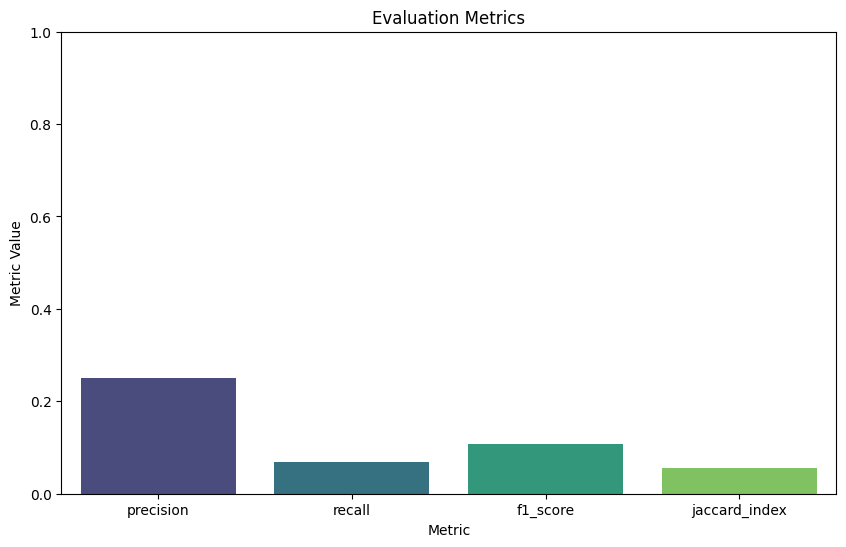

In [327]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert metrics to DataFrame for plotting
metrics_df = pd.DataFrame(list(metrics.items()), columns=['metric', 'value'])

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x='metric', y='value', data=metrics_df, palette='viridis')
plt.title('Evaluation Metrics')
plt.ylabel('Metric Value')
plt.xlabel('Metric')
plt.ylim(0, 1)  # Since metric values are between 0 and 1
plt.show()

## Token similarity metrics

In [328]:
grouped_df = filtered_edges.groupby('geneSymbol')['diseaseName'].apply(lambda x: x.tolist()).reset_index()
grouped_df

,geneSymbol,diseaseName
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca..."
...,...,...
266,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr..."
267,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm..."
268,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope..."
269,XRCC4,"[Autosome Abnormalities, Chromosome Aberration..."


In [330]:
import json

file_path = 'refined_output.jsonl'

# Initialize a dictionary to collect predicted diseases for each gene
predicted_diseases_dict2 = {}

# Open the file and read line by line
with open(file_path, 'r') as file:
    for line in file:
        # Parse the JSON object
        data = json.loads(line)
        
        # Extract the gene name from the "custom_id" field
        custom_id = data['custom_id']
        gene_name = custom_id.split('-')[1]  # Extracting the gene name part
        
        # Extract the diseases from the response body
        message_content = data['response']['body']['choices'][0]['message']['content']
        disease_list = message_content.split(", ")

        # Store the diseases in the dictionary under the gene name
        predicted_diseases_dict2[gene_name] = disease_list

# Print the dictionary of predicted diseases
print(predicted_diseases_dict2)

predicted = pd.DataFrame(list(predicted_diseases_dict2.items()), columns=['geneSymbol', 'diseaseName'])
predicted

{'ADAMTS10': ['Weill-Marchesani Syndrome - Autosomal Recessive', 'Hereditary Diffuse Gastric Cancer', 'Malignant neoplasm of liver', 'Malignant neoplasm of breast', 'Hereditary Non-Polyposis Colorectal Neoplasms', 'Malignant neoplasm of prostate', 'Lymphoma - Non-Hodgkin', 'Schizophrenia', 'Autism Spectrum Disorders', 'Venous Thromboembolism'], 'RPL35A': ['Hereditary Diffuse Gastric Cancer', 'Colorectal Carcinoma', 'Obesity', 'Malignant neoplasm of breast', 'Malignant neoplasm of prostate', 'Schizophrenia', 'Diabetes Mellitus - Non-Insulin-Dependent', 'Primary biliary cirrhosis', 'Malignant neoplasm of liver', 'Lupus Erythematosus - Systemic'], 'DOLK': ['Hereditary Diffuse Gastric Cancer', 'Myeloid Leukemia - Chronic', 'Autistic Disorder', 'Obesity', 'Congenital disorder of glycosylation type 1q', 'Schizophrenia', 'Malignant neoplasm of breast', 'Mitochondrial Myopathy', 'Leigh Syndrome', 'Liver carcinoma'], 'ACSL4': ['Liver carcinoma', 'Schizophrenia', 'Malignant neoplasm of breast', 

,geneSymbol,diseaseName
0,ADAMTS10,[Weill-Marchesani Syndrome - Autosomal Recessi...
1,RPL35A,"[Hereditary Diffuse Gastric Cancer, Colorectal..."
2,DOLK,"[Hereditary Diffuse Gastric Cancer, Myeloid Le..."
3,ACSL4,"[Liver carcinoma, Schizophrenia, Malignant neo..."
4,PIGN,"[Hereditary Diffuse Gastric Cancer, Lymphoma -..."
...,...,...
266,RASA2,"[IL6, RNASEH2A, FPN, TPSG, IL1B, CCL2, CTCF, M..."
267,RAD51D,"[Hereditary Diffuse Gastric Cancer, Breast Can..."
268,TGFA,"[Hereditary Diffuse Gastric Cancer, Colorectal..."
269,SEMA5A,"[Autism Spectrum Disorders, Autistic Disorder,..."


In [331]:
TS_df = pd.merge(grouped_df, predicted, on='geneSymbol', how='outer')
TS_df

,geneSymbol,diseaseName_x,diseaseName_y
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre..."
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo..."
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c..."
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M..."
...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam..."
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,..."
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ..."
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Myelodyspl..."


In [332]:
import pandas as pd
import numpy as np
from collections import Counter
import tiktoken

# BLEU score calculation functions
def ngrams(sequence, n):
    return [tuple(sequence[i:i+n]) for i in range(len(sequence)-n+1)]

def precision_n(reference, candidate, n):
    ref_ngrams = ngrams(reference, n)
    cand_ngrams = ngrams(candidate, n)

    ref_ngram_counts = Counter(ref_ngrams)
    cand_ngram_counts = Counter(cand_ngrams)

    matching_ngram_count = sum((cand_ngram_counts & ref_ngram_counts).values())
    total_cand_ngram_count = len(cand_ngrams)

    if total_cand_ngram_count == 0:
        return 0.0

    precision = matching_ngram_count / total_cand_ngram_count
    return precision

def brevity_penalty(reference, candidate):
    ref_len = len(reference)
    cand_len = len(candidate)

    if cand_len > ref_len:
        return 1
    elif cand_len == 0:
        return 0
    else:
        return np.exp(1 - ref_len / cand_len)

def calculate_bleu(reference, candidate, max_n=4):
    precisions = [precision_n(reference, candidate, n) for n in range(1, max_n + 1)]
    geo_mean_precision = np.exp(np.mean(np.log(precisions))) if precisions else 0.0
    bp = brevity_penalty(reference, candidate)

    bleu_score = bp * geo_mean_precision
    return bleu_score

def tokenize_list(disease_list, encoder):
    if isinstance(disease_list, float):
        return []
    return [encoder.encode(disease) for disease in disease_list]

# Tokenization function
def tokenize_text(text, encoder):
    return encoder.encode(text)


In [333]:
# Initialize encoder
encoder = tiktoken.get_encoding("gpt2")

# Function to calculate BLEU score for each row
def calculate_row_bleu(row):
    # Convert lists to comma-separated strings
    real_diseases_str = ', '.join(row['diseaseName_x']) if isinstance(row['diseaseName_x'], list) else row['diseaseName_x']
    predicted_diseases_str = ', '.join(row['diseaseName_y']) if isinstance(row['diseaseName_y'], list) else row['diseaseName_y']
    
    # Ensure they are strings
    if not isinstance(real_diseases_str, str):
        real_diseases_str = str(real_diseases_str)
    if not isinstance(predicted_diseases_str, str):
        predicted_diseases_str = str(predicted_diseases_str)
    
    # Tokenize the strings
    reference = tokenize_text(real_diseases_str, encoder)
    candidate = tokenize_text(predicted_diseases_str, encoder)
    
    # Calculate BLEU score
    return calculate_bleu(reference, candidate)

# Apply the function to each row in the DataFrame
TS_df['BLEU_score'] = TS_df.apply(calculate_row_bleu, axis=1)

TS_df

/var/folders/ps/w4c6pfcn4hn1n6vbjpq6794w0000gp/T/ipykernel_36817/1075495955.py:39: RuntimeWarning: divide by zero encountered in log
  geo_mean_precision = np.exp(np.mean(np.log(precisions))) if precisions else 0.0


,geneSymbol,diseaseName_x,diseaseName_y,BLEU_score
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre...",0.000000
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...",0.000000
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ...",0.095893
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c...",0.034666
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M...",0.000000
...,...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam...",0.159665
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,...",0.097054
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ...",0.000000
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Myelodyspl...",0.052982


In [334]:
average_BLEU = TS_df['BLEU_score'].mean()
print(average_BLEU)

0.046659935109874213


In [335]:
import pandas as pd
import numpy as np
from collections import Counter
import tiktoken

# Helper functions to calculate ROUGE-n
def ngrams(sequence, n):
    return [tuple(sequence[i:i+n]) for i in range(len(sequence)-n+1)]

def precision_n(reference, candidate, n):
    ref_ngrams = ngrams(reference, n)
    cand_ngrams = ngrams(candidate, n)

    ref_ngram_counts = Counter(ref_ngrams)
    cand_ngram_counts = Counter(cand_ngrams)

    matching_ngram_count = sum((cand_ngram_counts & ref_ngram_counts).values())
    total_cand_ngram_count = len(cand_ngrams)

    if total_cand_ngram_count == 0:
        return 0.0

    precision = matching_ngram_count / total_cand_ngram_count
    return precision

def recall_n(reference, candidate, n):
    ref_ngrams = ngrams(reference, n)
    cand_ngrams = ngrams(candidate, n)

    ref_ngram_counts = Counter(ref_ngrams)
    cand_ngram_counts = Counter(cand_ngrams)

    matching_ngram_count = sum((cand_ngram_counts & ref_ngram_counts).values())
    total_ref_ngram_count = len(ref_ngrams)

    if total_ref_ngram_count == 0:
        return 0.0

    recall = matching_ngram_count / total_ref_ngram_count
    return recall

def rouge_n(reference, candidate, n):
    precision = precision_n(reference, candidate, n)
    recall = recall_n(reference, candidate, n)

    if precision + recall == 0:
        return 0.0

    f1_score = 2 * precision * recall / (precision + recall)
    return f1_score

# Helper function to calculate ROUGE-L
def lcs(X, Y):
    m = len(X)
    n = len(Y)

    L = [[0] * (n+1) for i in range(m+1)]

    for i in range(m+1):
        for j in range(n+1):
            if i == 0 or j == 0:
                L[i][j] = 0
            elif X[i-1] == Y[j-1]:
                L[i][j] = L[i-1][j-1] + 1
            else:
                L[i][j] = max(L[i-1][j], L[i][j-1])

    return L[m][n]

def rouge_l(reference, candidate):
    lcs_length = lcs(reference, candidate)
    precision = lcs_length / len(candidate) if len(candidate) > 0 else 0.0
    recall = lcs_length / len(reference) if len(reference) > 0 else 0.0

    if precision + recall == 0:
        return 0.0

    f1_score = 2 * precision * recall / (precision + recall)
    return f1_score

# Tokenization function
def tokenize_text(text, encoder):
    return encoder.encode(text)


In [341]:
encoder = tiktoken.get_encoding("o200k_base")

# Function to calculate ROUGE scores for each row
def calculate_row_rouge(row):
    # Convert lists to comma-separated strings
    real_diseases_str = ', '.join(row['diseaseName_x']) if isinstance(row['diseaseName_x'], list) else row['diseaseName_x']
    predicted_diseases_str = ', '.join(row['diseaseName_y']) if isinstance(row['diseaseName_y'], list) else row['diseaseName_y']
    
    # Ensure they are strings
    if not isinstance(real_diseases_str, str):
        real_diseases_str = str(real_diseases_str)
    if not isinstance(predicted_diseases_str, str):
        predicted_diseases_str = str(predicted_diseases_str)
    
    # Tokenize the strings
    reference = tokenize_text(real_diseases_str, encoder)
    candidate = tokenize_text(predicted_diseases_str, encoder)
    
    # Calculate ROUGE scores
    rouge_1 = rouge_n(reference, candidate, 1)
    rouge_2 = rouge_n(reference, candidate, 2)
    rouge_l_score = rouge_l(reference, candidate)
    
    return pd.Series([rouge_1, rouge_2, rouge_l_score])

# Apply the function to each row in the DataFrame
TS_df[['ROUGE_1', 'ROUGE_2', 'ROUGE_L']] = TS_df.apply(calculate_row_rouge, axis=1)

TS_df

,geneSymbol,diseaseName_x,diseaseName_y,BLEU_score,ROUGE_1,ROUGE_2,ROUGE_L
0,A2ML1,"[Otitis Media, LEOPARD Syndrome, Costello synd...","[Hereditary Diffuse Gastric Cancer, Schizophre...",0.000000,0.140000,0.061224,0.140000
1,AAGAB,"[Punctate keratosis, Meleda Disease, Keratoder...","[Lymphoma - Non-Hodgkin, Hereditary Non-Polypo...",0.000000,0.095238,0.019417,0.095238
2,ABCB11,"[Afibrinogenemia, Cholestasis, Intrahepatic Ch...","[Hereditary Diffuse Gastric Cancer, Malignant ...",0.095893,0.209150,0.092715,0.196078
3,ABCB4,"[Cholangitis, Primary biliary cirrhosis, Chola...","[Hereditary Diffuse Gastric Cancer, Squamous c...",0.034666,0.228571,0.100719,0.135714
4,ABCG8,"[Blood Platelet Disorders, Common Bile Duct Ca...","[Hereditary Diffuse Gastric Cancer, Obesity, M...",0.000000,0.214286,0.028986,0.171429
...,...,...,...,...,...,...,...
268,WNT10B,"[Malignant neoplasm of breast, Neoplasm Recurr...","[Cleft upper lip, Obesity, Breast Cancer - Fam...",0.159665,0.327586,0.175439,0.189655
269,WNT4,"[Dwarfism, Kidney Diseases, Prostatic Neoplasm...","[Hereditary Nonpolyposis Colorectal Neoplasms,...",0.097054,0.253968,0.129032,0.206349
270,WRAP53,"[Body Weight, Dyskeratosis Congenita, Neutrope...","[Hereditary Diffuse Gastric Cancer, Malignant ...",0.000000,0.084211,0.000000,0.084211
271,XRCC4,"[Autosome Abnormalities, Chromosome Aberration...","[Hereditary Diffuse Gastric Cancer, Myelodyspl...",0.052982,0.206522,0.109890,0.141304


In [342]:
average_R1 = TS_df['ROUGE_1'].mean()
print(average_R1)

average_R2 = TS_df['ROUGE_2'].mean()
print(average_R2)

average_RL = TS_df['ROUGE_L'].mean()
print(average_RL)

0.18289116302903274
0.08506073488429824
0.14165941688751382
